In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from tqdm import tqdm

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#      (os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
import os
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
from glob import glob
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# PATHS
BASE = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup'
STEMS = os.path.join(BASE, 'genres_stems')
ESC_AUDIO = os.path.join(BASE, 'ESC-50-master', 'audio')
MASHUPS = os.path.join(BASE, 'mashups')

GENRES = ['blues', 'classical', 'country', 'disco', 'hiphop',
          'jazz', 'metal', 'pop', 'reggae', 'rock']
STEM_NAMES = ['drums.wav', 'vocals.wav', 'bass.wav', 'others.wav']

# HELPER: Collect all stem file paths
def get_all_stem_paths():
    """Return list of (genre, song_folder, stem_name, full_path)"""
    all_paths = []
    for genre in GENRES:
        genre_dir = os.path.join(STEMS, genre)
        if not os.path.isdir(genre_dir):
            continue
        for song in sorted(os.listdir(genre_dir)):
            song_dir = os.path.join(genre_dir, song)
            if not os.path.isdir(song_dir):
                continue
            for stem in STEM_NAMES:
                fpath = os.path.join(song_dir, stem)
                if os.path.exists(fpath):
                    all_paths.append((genre, song, stem, fpath))
    return all_paths

all_stem_files = get_all_stem_paths()
print(f"Total stem files found: {len(all_stem_files)}")

# Q1: Mean duration (seconds) of Jazz genre stems
print("\n" + "="*60)
print("Q1: Mean duration of Jazz genre stems")
print("="*60)

jazz_durations = []
for genre, song, stem, fpath in tqdm(all_stem_files, desc="Q1 Jazz duration"):
    if genre == 'jazz':
        try:
            info = sf.info(fpath)
            jazz_durations.append(info.duration)
        except:
            try:
                y, sr = librosa.load(fpath, sr=None)
                jazz_durations.append(len(y) / sr)
            except:
                pass

mean_jazz_dur = np.mean(jazz_durations)
print(f"  Jazz stem count: {len(jazz_durations)}")
print(f"  >>> ANSWER Q1: Mean duration of Jazz stems = {mean_jazz_dur:.4f} seconds")

# Q2: Unique sample rates in the ENTIRE dataset
print("\n" + "="*60)
print("Q2: Unique sample rates across entire dataset")
print("="*60)

sample_rates = set()

# --- Genre stems ---
print("  Scanning genre stems...")
for genre, song, stem, fpath in tqdm(all_stem_files, desc="Q2 stems SR"):
    try:
        info = sf.info(fpath)
        sample_rates.add(info.samplerate)
    except:
        try:
            y, sr = librosa.load(fpath, sr=None)
            sample_rates.add(sr)
        except:
            pass

# --- ESC-50 noise ---
print("  Scanning ESC-50 audio...")
esc_files = glob(os.path.join(ESC_AUDIO, '*.wav'))
for fpath in tqdm(esc_files, desc="Q2 ESC SR"):
    try:
        info = sf.info(fpath)
        sample_rates.add(info.samplerate)
    except:
        try:
            y, sr = librosa.load(fpath, sr=None)
            sample_rates.add(sr)
        except:
            pass

# --- Mashups ---
print("  Scanning mashups...")
mashup_files = glob(os.path.join(MASHUPS, '*.wav'))
for fpath in tqdm(mashup_files, desc="Q2 mashup SR"):
    try:
        info = sf.info(fpath)
        sample_rates.add(info.samplerate)
    except:
        try:
            y, sr = librosa.load(fpath, sr=None)
            sample_rates.add(sr)
        except:
            pass

sorted_sr = sorted(sample_rates)
print(f"  >>> ANSWER Q2: Unique sample rates = {sorted_sr}")

# Q3: Empty or zero-byte audio files in train dataset
print("\n" + "="*60)
print("Q3: Empty or zero-byte audio files in train dataset")
print("="*60)

zero_byte_count = 0
for genre, song, stem, fpath in tqdm(all_stem_files, desc="Q3 zero-byte"):
    fsize = os.path.getsize(fpath)
    if fsize == 0:
        zero_byte_count += 1
        print(f"    Found zero-byte: {fpath}")

print(f"  >>> ANSWER Q3: Number of empty/zero-byte files = {zero_byte_count}")

# Q4: Average peak amplitude (dB) for vocal stems in train
print("\n" + "="*60)
print("Q4: Average peak amplitude (dB) for vocal stems")
print("="*60)

vocal_peak_dbs = []
for genre, song, stem, fpath in tqdm(all_stem_files, desc="Q4 vocal peak"):
    if stem == 'vocals.wav':
        try:
            y, sr = librosa.load(fpath, sr=None)
            peak = np.max(np.abs(y))
            if peak > 0:
                peak_db = 20 * np.log10(peak)
            else:
                peak_db = -np.inf
            vocal_peak_dbs.append(peak_db)
        except:
            pass

# Filter out -inf for mean calculation if needed
finite_peaks = [p for p in vocal_peak_dbs if np.isfinite(p)]
avg_peak_db = np.mean(vocal_peak_dbs) if all(np.isfinite(vocal_peak_dbs)) else np.mean(finite_peaks)
avg_peak_db_all = np.mean(vocal_peak_dbs)  # including -inf if any

print(f"  Vocal stem files processed: {len(vocal_peak_dbs)}")
print(f"  Finite peak values: {len(finite_peaks)}")
print(f"  >>> ANSWER Q4: Average peak amplitude (dB) for vocals = {np.mean(finite_peaks):.4f} dB")
print(f"  (If including -inf entries as -inf: {avg_peak_db_all})")

# Q5: Mean spectral centroid for 'blues' genre
# Q6: Genre with highest mean spectral centroid
print("\n" + "="*60)
print("Q5 & Q6: Spectral centroid per genre")
print("="*60)

genre_centroids = {g: [] for g in GENRES}

for genre, song, stem, fpath in tqdm(all_stem_files, desc="Q5/Q6 spectral centroid"):
    try:
        y, sr = librosa.load(fpath, sr=None)
        if len(y) == 0:
            continue
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        mean_centroid = np.mean(centroid)
        genre_centroids[genre].append(mean_centroid)
    except:
        pass

genre_mean_centroid = {}
for g in GENRES:
    if len(genre_centroids[g]) > 0:
        genre_mean_centroid[g] = np.mean(genre_centroids[g])
    else:
        genre_mean_centroid[g] = 0.0
    print(f"  {g:12s}: mean spectral centroid = {genre_mean_centroid[g]:.4f} Hz  (n={len(genre_centroids[g])})")

blues_centroid = genre_mean_centroid.get('blues', 0)
highest_genre = max(genre_mean_centroid, key=genre_mean_centroid.get)

print(f"\n  >>> ANSWER Q5: Mean spectral centroid for 'blues' = {blues_centroid:.4f} Hz")
print(f"  >>> ANSWER Q6: Genre with highest mean spectral centroid = '{highest_genre}' ({genre_mean_centroid[highest_genre]:.4f} Hz)")

# Q7: Stem files with silence in first 0.5 seconds
print("\n" + "="*60)
print("Q7: Stems with silence in first 0.5 seconds (max|amp| < 1e-4)")
print("="*60)

silence_count = 0
for genre, song, stem, fpath in tqdm(all_stem_files, desc="Q7 silence check"):
    try:
        y, sr = librosa.load(fpath, sr=None)
        # First 0.5 seconds
        n_samples = int(0.5 * sr)
        first_half_sec = y[:n_samples]
        if len(first_half_sec) == 0:
            silence_count += 1
            continue
        max_amp = np.max(np.abs(first_half_sec))
        if max_amp < 1e-4:
            silence_count += 1
    except:
        pass

print(f"  >>> ANSWER Q7: Stem files with silence in first 0.5s = {silence_count}")

# SUMMARY
print("\n" + "="*60)
print("SUMMARY OF ALL ANSWERS")
print("="*60)
print(f"Q1: Mean duration of Jazz stems           = {mean_jazz_dur:.4f} seconds")
print(f"Q2: Unique sample rates                    = {sorted_sr}")
print(f"Q3: Empty/zero-byte files in train         = {zero_byte_count}")
print(f"Q4: Avg peak amplitude (dB) vocal stems    = {np.mean(finite_peaks):.4f} dB")
print(f"Q5: Mean spectral centroid for blues        = {blues_centroid:.4f} Hz")
print(f"Q6: Genre with highest mean spectral centroid = {highest_genre}")
print(f"Q7: Stems with silence in first 0.5s       = {silence_count}")

Total stem files found: 3000

Q1: Mean duration of Jazz genre stems


Q1 Jazz duration: 100%|██████████| 3000/3000 [00:00<00:00, 7161.35it/s] 


  Jazz stem count: 300
  >>> ANSWER Q1: Mean duration of Jazz stems = 30.0330 seconds

Q2: Unique sample rates across entire dataset
  Scanning genre stems...


Q2 stems SR: 100%|██████████| 3000/3000 [00:03<00:00, 869.29it/s] 


  Scanning ESC-50 audio...


...

  Vocal stem files processed: 1000
  Finite peak values: 1000
  >>> ANSWER Q4: Average peak amplitude (dB) for vocals = -12.4949 dB
  (If including -inf entries as -inf: -12.49492073059082)

Q5 & Q6: Spectral centroid per genre


Q5/Q6 spectral centroid: 100%|██████████| 3000/3000 [05:42<00:00,  8.75it/s]


  blues       : mean spectral centroid = 2533.2226 Hz  (n=300)
  classical   : mean spectral centroid = 1789.9198 Hz  (n=300)
  country     : mean spectral centroid = 2577.7795 Hz  (n=300)
  disco       : mean spectral centroid = 2675.8654 Hz  (n=300)
  hiphop      : mean spectral centroid = 2259.4799 Hz  (n=300)
  jazz        : mean spectral centroid = 2882.5444 Hz  (n=300)
  metal       : mean spectral centroid = 2642.9020 Hz  (n=300)
  pop         : mean spectral centroid = 2734.3862 Hz  (n=300)
  reggae      : mean spectral centroid = 2585.5119 Hz  (n=300)
  rock        : mean spectral centroid = 2493.2512 Hz  (n=300)

  >>> ANSWER Q5: Mean spectral centroid for 'blues' = 2533.2226 Hz
  >>> ANSWER Q6: Genre with highest mean spectral centroid = 'jazz' (2882.5444 Hz)

Q7: Stems with silence in first 0.5 seconds (max|amp| < 1e-4)


Q7 silence check: 100%|██████████| 3000/3000 [02:43<00:00, 18.32it/s]

  >>> ANSWER Q7: Stem files with silence in first 0.5s = 332

SUMMARY OF ALL ANSWERS
Q1: Mean duration of Jazz stems           = 30.0330 seconds
Q2: Unique sample rates                    = [22050, 44100]
Q3: Empty/zero-byte files in train         = 0
Q4: Avg peak amplitude (dB) vocal stems    = -12.4949 dB
Q5: Mean spectral centroid for blues        = 2533.2226 Hz
Q6: Genre with highest mean spectral centroid = jazz
Q7: Stems with silence in first 0.5s       = 332


/tmp/ipykernel_92/4206418603.py:38: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return [float(tempo), spec_cent, zcr, rolloff]
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_cla

Q9  (Validation Macro F1 Score): 0.1523
Q10 (Precision of hiphop): 0.2500
Q11 (Recall of pop): 0.2000
Q12 (Model Accuracy): 0.1900
Q13 (Genre with highest TP): metal
Q14 (Genre with lowest FN): metal


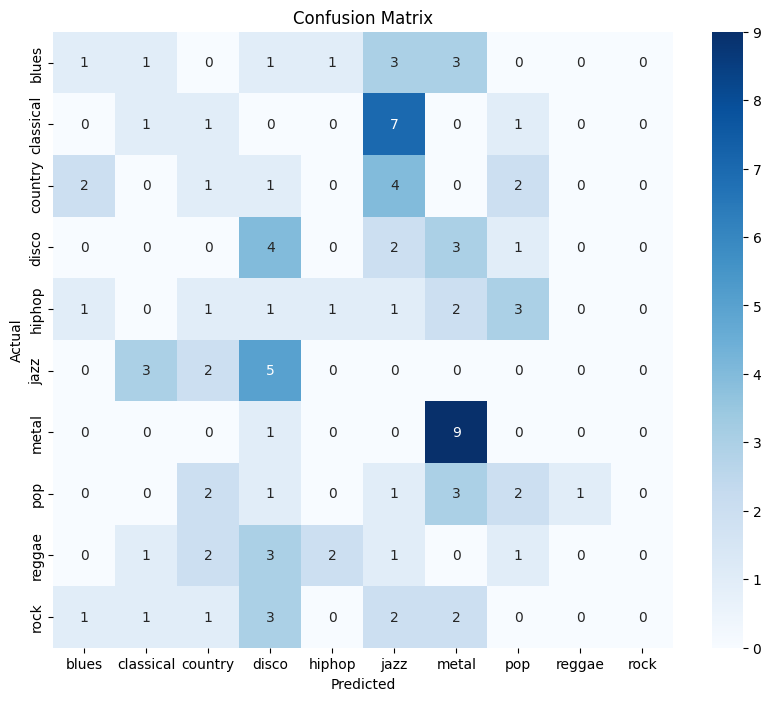

In [ ]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report, accuracy_score

# --- 1. Setup and Preprocessing ---
ROOT = '/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup'
STEMS_PATH = os.path.join(ROOT, 'genres_stems')
GENRES = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]

def extract_features(song_path):
    possible_files = ['others.wav', 'other.wav']

    audio_path = None
    for f in possible_files:
        p = os.path.join(song_path, f)
        if os.path.exists(p):
            audio_path = p
            break

    # If no valid file found → skip safely
    if audio_path is None:
        return None

    try:
        y, sr = librosa.load(audio_path, sr=22050, duration=10)

        tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
        spec_cent = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
        zcr = np.mean(librosa.feature.zero_crossing_rate(y))
        rolloff = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))

        return [float(tempo), spec_cent, zcr, rolloff]

    except:
        return None

# --- 2. Data Preparation ---
data = []
for g in GENRES:
    gp = os.path.join(STEMS_PATH, g)
    songs = [s for s in os.listdir(gp) if os.path.isdir(os.path.join(gp, s))]
    for s in songs[:50]:  # keep 50 for speed
        data.append({'path': os.path.join(gp, s), 'genre': g})

df = pd.DataFrame(data)

train_df, val_df = train_test_split(
    df, test_size=0.2, stratify=df['genre'], random_state=42
)

# --- 3. Feature Extraction ---
X_train = np.array([extract_features(p) for p in train_df['path']])
y_train = train_df['genre']

X_val = np.array([extract_features(p) for p in val_df['path']])
y_val = val_df['genre']

# --- 4. Model ---
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

# --- 5. Evaluation ---
y_pred = clf.predict(X_val)

macro_f1 = f1_score(y_val, y_pred, average='macro')
cm = confusion_matrix(y_val, y_pred, labels=GENRES)
cr_dict = classification_report(y_val, y_pred, labels=GENRES, output_dict=True)

accuracy = accuracy_score(y_val, y_pred)

# --- 6. Extract Required Answers ---

# Precision of hiphop
precision_hiphop = cr_dict['hiphop']['precision']

# Recall of pop
recall_pop = cr_dict['pop']['recall']

# TP, FP, FN, TN
tp = np.diag(cm)
fp = np.sum(cm, axis=0) - tp
fn = np.sum(cm, axis=1) - tp
tn = np.sum(cm) - (tp + fp + fn)

metrics_df = pd.DataFrame({
    "Genre": GENRES,
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn
})

# Genre with highest TP
genre_highest_tp = metrics_df.loc[metrics_df['TP'].idxmax(), 'Genre']

# Genre with lowest FN
genre_lowest_fn = metrics_df.loc[metrics_df['FN'].idxmin(), 'Genre']

# --- 7. Print Final Answers ---

print(f"Q9  (Validation Macro F1 Score): {macro_f1:.4f}")
print(f"Q10 (Precision of hiphop): {precision_hiphop:.4f}")
print(f"Q11 (Recall of pop): {recall_pop:.4f}")
print(f"Q12 (Model Accuracy): {accuracy:.4f}")
print(f"Q13 (Genre with highest TP): {genre_highest_tp}")
print(f"Q14 (Genre with lowest FN): {genre_lowest_fn}")

# --- 8. Confusion Matrix Plot ---
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=GENRES, yticklabels=GENRES, cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()